In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/main/day42-outlier-removal-using-zscore/placement.csv"
)

In [3]:
df.shape

(1000, 3)

<Axes: xlabel='placement_exam_marks', ylabel='Density'>

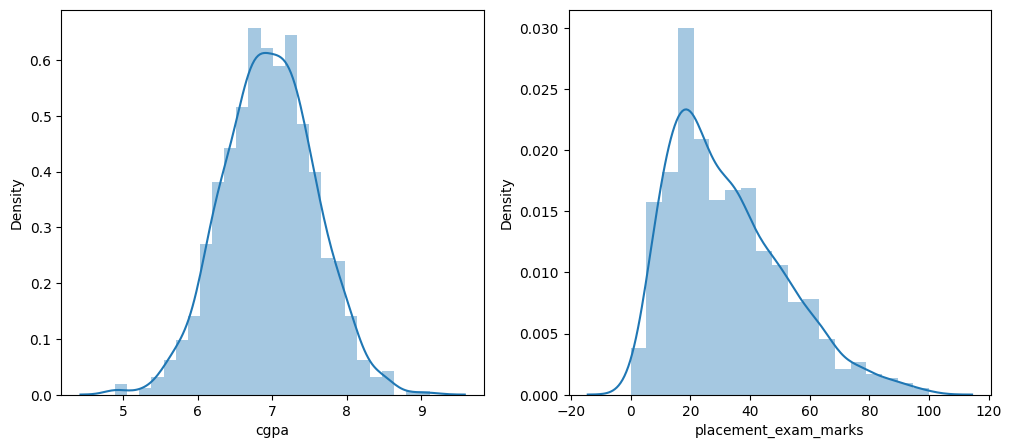

In [4]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'])

plt.subplot(1,2,2)

sns.distplot(df['placement_exam_marks'])

<Axes: xlabel='placement_exam_marks'>

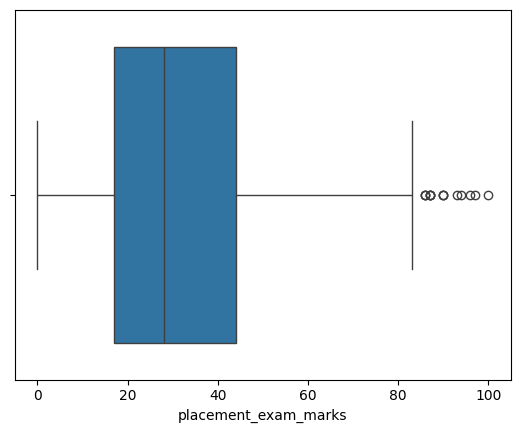

In [5]:
sns.boxplot(df['placement_exam_marks'],orient='h')

## Finding the IQR

In [6]:
Q1 = df['placement_exam_marks'].quantile(0.25)
Q3 = df['placement_exam_marks'].quantile(0.75)

## or

In [21]:
q1,q3=np.percentile(df['placement_exam_marks'],[25,75])

In [8]:
iqr = (Q3 - Q1) 

In [9]:
upper_limit  =  Q3 + 1.5*iqr 
lower_limit  =  Q1 - 1.5*iqr

In [10]:
print("upper_limit  = " , Q3 + 1.5*iqr )
print("lower_limit  = " , Q1 - 1.5*iqr )

upper_limit  =  84.5
lower_limit  =  -23.5


## Finding outlier 

In [11]:
df[df['placement_exam_marks'] > upper_limit ]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [12]:
df[df['placement_exam_marks'] < lower_limit ]

,cgpa,placement_exam_marks,placed


## Trimming

In [13]:
new_df=df[(df['placement_exam_marks'] < upper_limit ) & (df['placement_exam_marks'] > lower_limit) ]

In [14]:
new_df.shape

(985, 3)

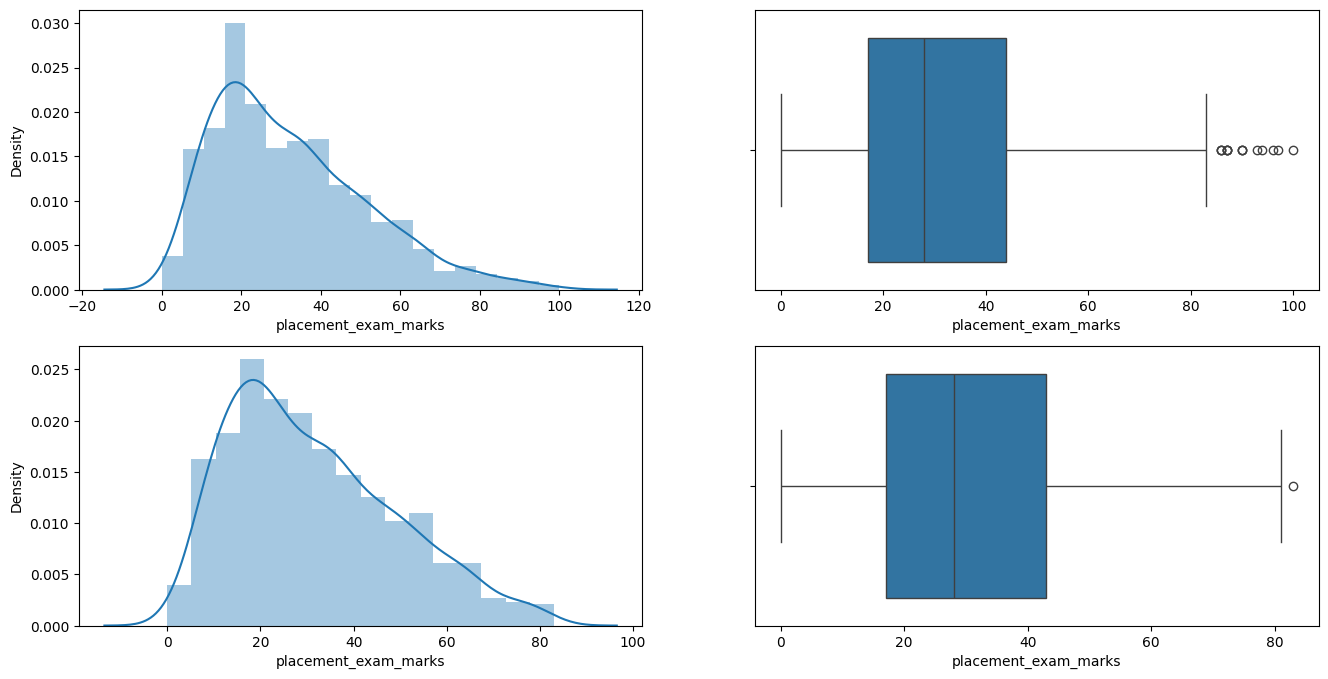

In [15]:
# Comparing

plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.distplot(df['placement_exam_marks'])

plt.subplot(2,2,2)
sns.boxplot(df['placement_exam_marks'],orient='h')

plt.subplot(2,2,3)
sns.distplot(new_df['placement_exam_marks'])

plt.subplot(2,2,4)
sns.boxplot(new_df['placement_exam_marks'],orient='h')

plt.show()

## Capping 

In [16]:
new_df_cap=df.copy()
new_df_cap['placement_exam_marks']=np.where(new_df_cap['placement_exam_marks'] > upper_limit , upper_limit ,
                    np.where(new_df_cap['placement_exam_marks'] < lower_limit , lower_limit ,new_df_cap['placement_exam_marks'])
                   )

In [17]:
new_df_cap.shape

(1000, 3)

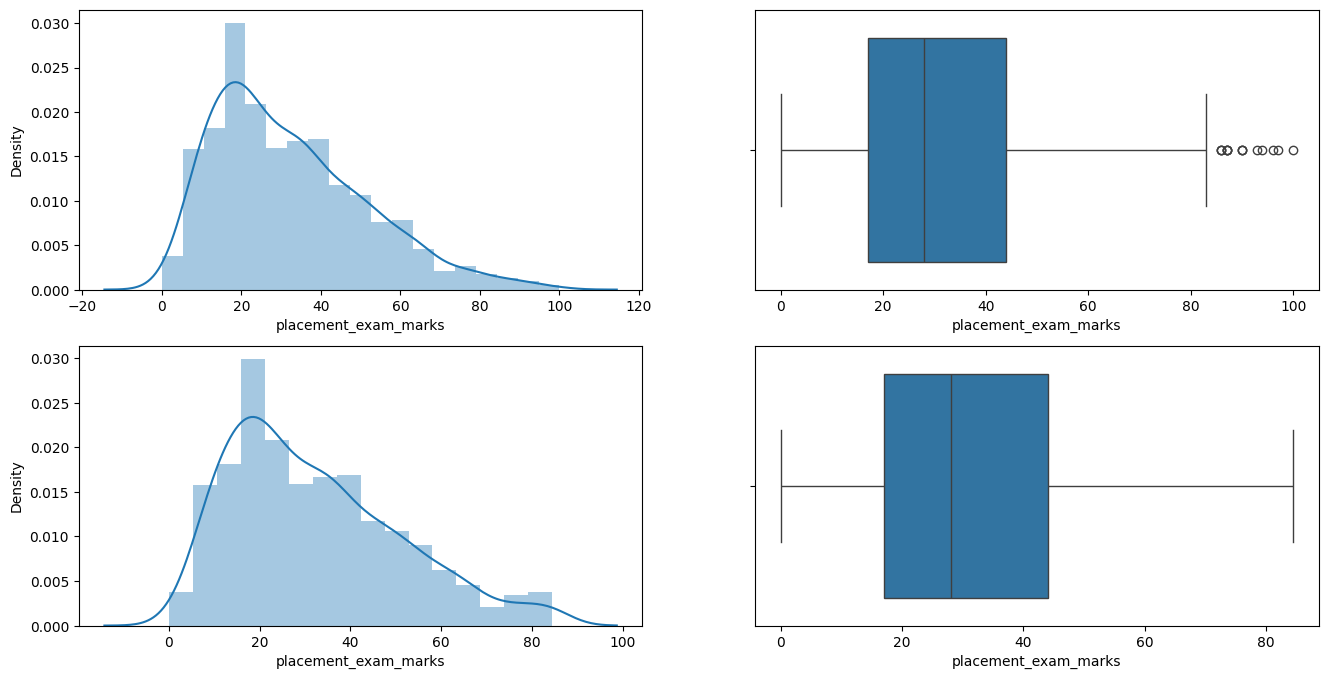

In [18]:
# Comparing

plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.distplot(df['placement_exam_marks'])

plt.subplot(2,2,2)
sns.boxplot(df['placement_exam_marks'],orient='h')

plt.subplot(2,2,3)
sns.distplot(new_df_cap['placement_exam_marks'])

plt.subplot(2,2,4)
sns.boxplot(new_df_cap['placement_exam_marks'],orient='h')

plt.show()